# 01 · La neurona artificial

**Objetivo:** construir una sola neurona desde cero con NumPy, entender cada función de activación que encontrarás en la IA moderna (escalón, sigmoide, tanh, ReLU, Leaky ReLU, ELU, GELU, SiLU/Swish, softmax) y entrenar una neurona con descenso de gradiente.

**Contenido**
1. De la biología a las matemáticas
2. Una neurona en 10 líneas de NumPy
3. Funciones de activación (y sus derivadas)
4. Por qué importa la no linealidad
5. Saturación, gradientes que se desvanecen y ReLU muertas
6. Una neurona como compuerta lógica (y por qué XOR la rompe)
7. Entrenar una neurona: la regla del perceptrón y el descenso de gradiente
8. Ejercicios

Todo lo que hay aquí se ejecuta en la CPU de un equipo personal en pocos segundos.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(0)
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. De la biología a las matemáticas

Una neurona biológica recibe señales a través de sus **dendritas**, las suma en el **cuerpo celular** y, si el total supera un umbral, **dispara** un pulso eléctrico a lo largo de su **axón**.

La neurona artificial (McCulloch y Pitts 1943, Rosenblatt 1958) conserva solo lo esencial:

$$
z = \sum_{i=1}^{n} w_i x_i + b = \mathbf{w}^\top \mathbf{x} + b \qquad\qquad a = f(z)
$$

| Símbolo | Nombre | Papel |
|---|---|---|
| $\mathbf{x}$ | entradas | las señales que llegan a la neurona |
| $\mathbf{w}$ | pesos | cuánto importa cada entrada (se aprenden) |
| $b$ | sesgo (bias) | desplaza el umbral (se aprende) |
| $z$ | preactivación / logit | la suma ponderada |
| $f$ | función de activación | decide la forma de la salida (no lineal) |
| $a$ | activación / salida | lo que la neurona "dice" |

Geométricamente, $\mathbf{w}^\top\mathbf{x} + b = 0$ es un **hiperplano** (una recta en 2D). Una sola neurona divide su espacio de entrada en dos mitades, y la función de activación decide qué tan brusca es esa división.

## 2. Una neurona en 10 líneas de NumPy

In [2]:
class Neuron:
    def __init__(self, n_inputs, activation):
        self.w = np.random.randn(n_inputs) * 0.5   # pesos aleatorios pequeños
        self.b = 0.0
        self.activation = activation

    def forward(self, x):
        z = x @ self.w + self.b                   # suma ponderada (funciona con una muestra o con un lote)
        return self.activation(z)

identity = lambda z: z
n = Neuron(3, identity)
x = np.array([1.0, 2.0, -1.0])
print("pesos:", n.w.round(3), " sesgo:", n.b)
print("salida:", n.forward(x).round(3))
print("control:", (x * n.w).sum().round(3))

pesos: [0.882 0.2   0.489]  sesgo: 0.0
salida: 0.793
control: 0.793


## 3. Funciones de activación

La función de activación es lo que hace que las redes neuronales sean más potentes que una regresión lineal. Abajo se implementa cada una junto con su **derivada**, porque el entrenamiento (notebook 02) necesita la derivada.

| Función | Fórmula | Rango | Dónde se usa |
|---|---|---|---|
| Escalón (Heaviside) | $1$ si $z>0$, si no $0$ | {0,1} | perceptrón original; no es derivable |
| Sigmoide | $\sigma(z)=\frac{1}{1+e^{-z}}$ | (0,1) | salidas binarias, compuertas de las LSTM |
| Tanh | $\tanh(z)$ | (-1,1) | RNN, MLP más antiguos |
| ReLU | $\max(0,z)$ | [0,∞) | la opción por defecto en CNN y MLP |
| Leaky ReLU | $\max(\alpha z, z)$ | (-∞,∞) | corrige las ReLU "muertas" |
| ELU | $z$ si $z>0$, si no $\alpha(e^z-1)$ | (-α,∞) | lado negativo suave |
| GELU | $z\,\Phi(z)$ | ≈(-0.17,∞) | BERT, GPT-2/3, la mayoría de los transformers |
| SiLU / Swish | $z\,\sigma(z)$ | ≈(-0.28,∞) | LLaMA (dentro de SwiGLU), EfficientNet |
| Softmax | $\frac{e^{z_i}}{\sum_j e^{z_j}}$ | probabilidades | capa de salida multiclase, atención |

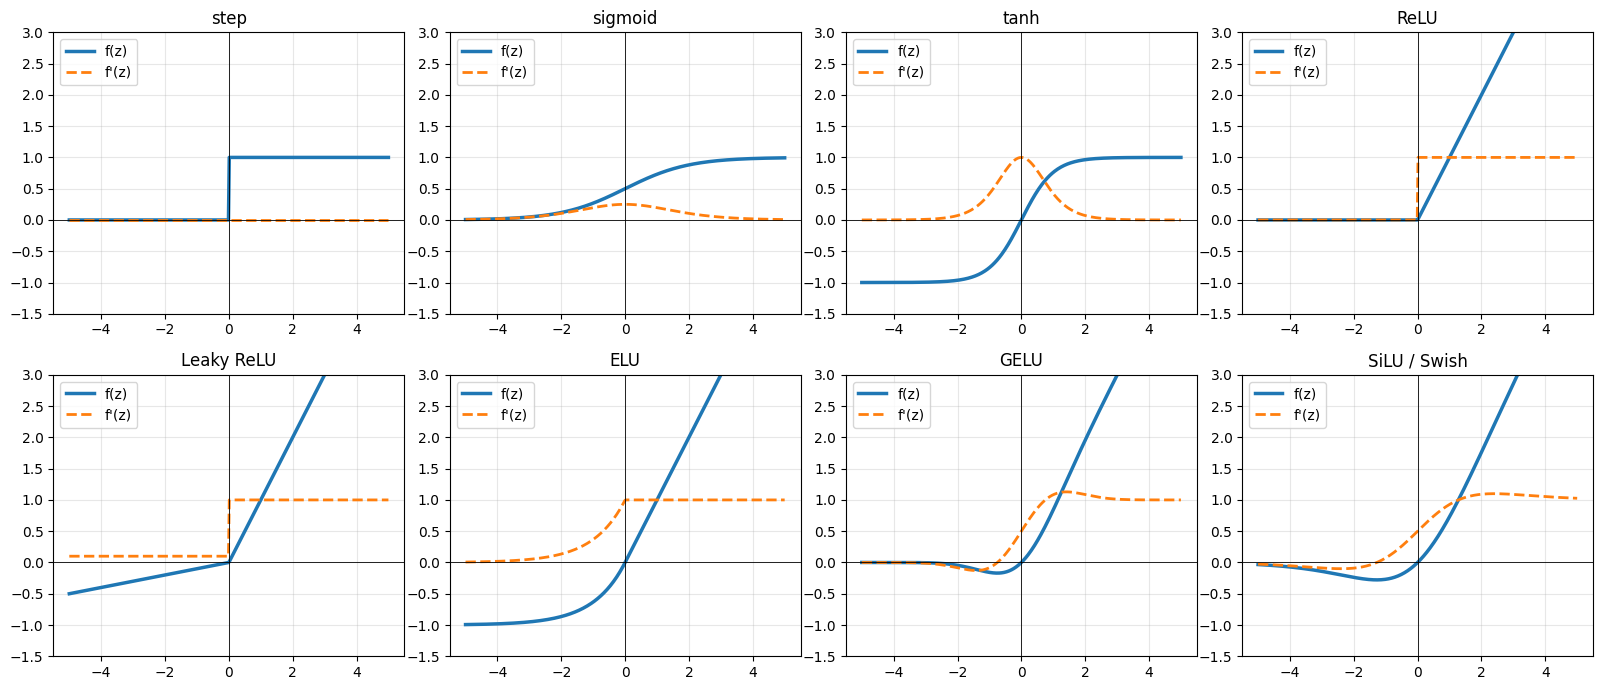

In [3]:
from math import erf, sqrt, pi
_erf = np.vectorize(erf)

def step(z):        return (z > 0).astype(float)
def d_step(z):      return np.zeros_like(z)               # cero en todas partes (indefinida en 0): inútil para el descenso de gradiente

def sigmoid(z):     return 1 / (1 + np.exp(-z))
def d_sigmoid(z):   s = sigmoid(z); return s * (1 - s)

def tanh(z):        return np.tanh(z)
def d_tanh(z):      return 1 - np.tanh(z) ** 2

def relu(z):        return np.maximum(0, z)
def d_relu(z):      return (z > 0).astype(float)

def leaky_relu(z, a=0.1):   return np.where(z > 0, z, a * z)
def d_leaky_relu(z, a=0.1): return np.where(z > 0, 1.0, a)

def elu(z, a=1.0):   return np.where(z > 0, z, a * (np.exp(z) - 1))
def d_elu(z, a=1.0): return np.where(z > 0, 1.0, a * np.exp(z))

def gelu(z):        return 0.5 * z * (1 + _erf(z / sqrt(2)))   # exacta: z * Phi(z)
def d_gelu(z):
    Phi = 0.5 * (1 + _erf(z / sqrt(2)))
    phi = np.exp(-z ** 2 / 2) / sqrt(2 * pi)
    return Phi + z * phi

def silu(z):        return z * sigmoid(z)
def d_silu(z):      s = sigmoid(z); return s + z * s * (1 - s)

ACTS = {
    "step": (step, d_step), "sigmoid": (sigmoid, d_sigmoid), "tanh": (tanh, d_tanh),
    "ReLU": (relu, d_relu), "Leaky ReLU": (leaky_relu, d_leaky_relu), "ELU": (elu, d_elu),
    "GELU": (gelu, d_gelu), "SiLU / Swish": (silu, d_silu),
}

z = np.linspace(-5, 5, 400)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, (name, (f, df)) in zip(axes.ravel(), ACTS.items()):
    ax.plot(z, f(z), lw=2.5, label="f(z)")
    ax.plot(z, df(z), "--", lw=2, label="f'(z)")
    ax.axhline(0, color="k", lw=0.6); ax.axvline(0, color="k", lw=0.6)
    ax.set_title(name); ax.set_ylim(-1.5, 3); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

### Comprobar las derivadas numéricamente

Un buen hábito: cada vez que escribas una derivada a mano, compárala con la **diferencia finita** $\frac{f(z+h)-f(z-h)}{2h}$. Reutilizaremos este truco para verificar la retropropagación en el notebook 02.

In [4]:
zs = np.linspace(-3, 3, 13) + 0.013     # evitamos el 0 exacto, donde están los quiebres tipo ReLU
h = 1e-5
for name, (f, df) in ACTS.items():
    if name == "step":
        continue
    numeric = (f(zs + h) - f(zs - h)) / (2 * h)
    print(f"{name:13s} max |analytic - numeric| = {np.abs(numeric - df(zs)).max():.2e}")

sigmoid       max |analytic - numeric| = 7.95e-12
tanh          max |analytic - numeric| = 3.34e-11
ReLU          max |analytic - numeric| = 6.55e-12
Leaky ReLU    max |analytic - numeric| = 6.55e-12
ELU           max |analytic - numeric| = 1.09e-11
GELU          max |analytic - numeric| = 1.65e-11
SiLU / Swish  max |analytic - numeric| = 1.35e-11


### Softmax: una activación para una *capa*, no para una sola neurona

Softmax convierte un vector de puntuaciones (logits) en una distribución de probabilidad. Se usa a la salida de los clasificadores y, sobre todo, **dentro de la atención** (notebook 07). Dos detalles prácticos:

* **Estabilidad numérica:** resta $\max(z)$ antes de exponenciar. El resultado es idéntico, pero sin desbordamiento.
* **Temperatura $T$:** $\text{softmax}(z/T)$. $T$ pequeña → distribución puntiaguda (segura), $T$ grande → distribución plana (insegura). Es exactamente el parámetro de "temperatura" de los modelos tipo ChatGPT (notebook 08).

exp ingenua con logits enormes desborda: [inf]
softmax estable con logits enormes    : [0.7311 0.2689]


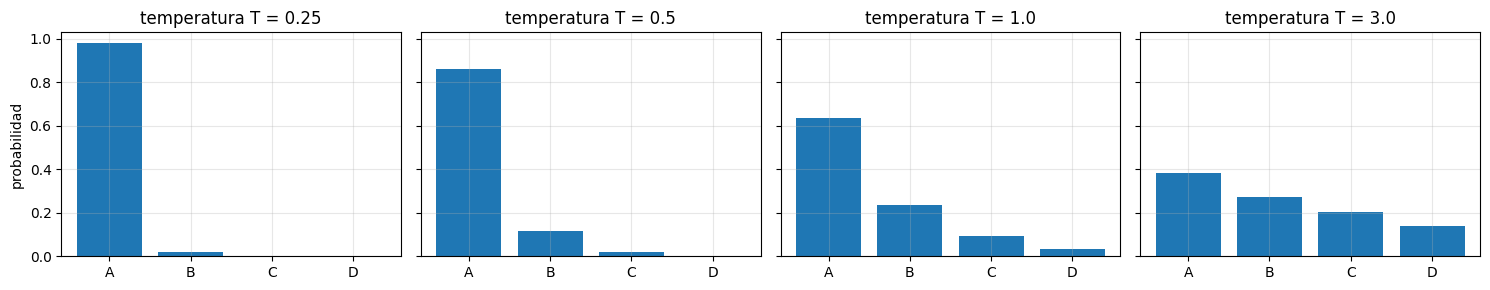

In [5]:
def softmax(z, T=1.0):
    z = np.asarray(z, dtype=float) / T
    z = z - z.max(axis=-1, keepdims=True)           # truco de estabilidad
    e = np.exp(z)
    return e / e.sum(axis=-1, keepdims=True)

logits = np.array([2.0, 1.0, 0.1, -1.0])
print("exp ingenua con logits enormes desborda:", np.exp(np.array([1000.0])))
print("softmax estable con logits enormes    :", softmax([1000.0, 999.0]).round(4))

fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, T in zip(axes, [0.25, 0.5, 1.0, 3.0]):
    ax.bar(["A", "B", "C", "D"], softmax(logits, T), color="tab:blue")
    ax.set_title(f"temperatura T = {T}")
axes[0].set_ylabel("probabilidad"); plt.tight_layout(); plt.show()

## 4. Por qué importa la no linealidad

Si $f$ es la identidad, apilar capas no aporta nada: $W_2(W_1 x + b_1) + b_2 = (W_2W_1)x + (W_2 b_1 + b_2)$ **sigue siendo una única transformación lineal**. Una red lineal de 100 capas es exactamente igual de expresiva que una sola capa.

Con una no linealidad entre capas, la red puede doblar el espacio. La celda de abajo verifica ambas afirmaciones numéricamente.

dos capas lineales == una capa lineal: True


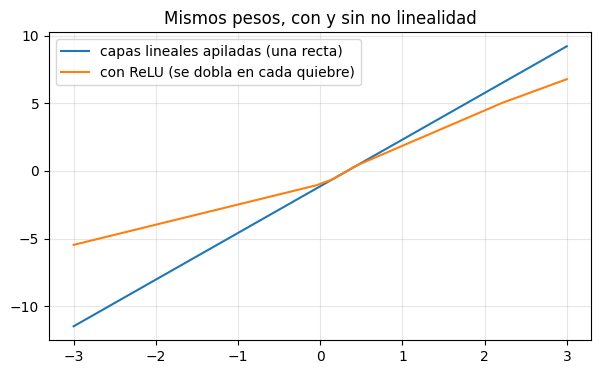

In [6]:
W1, b1 = np.random.randn(5, 2), np.random.randn(5)
W2, b2 = np.random.randn(1, 5), np.random.randn(1)

X = np.random.randn(100, 2)
deep_linear = (X @ W1.T + b1) @ W2.T + b2
W, b = W2 @ W1, W2 @ b1 + b2                          # se colapsa en una sola capa
print("dos capas lineales == una capa lineal:", np.allclose(deep_linear, X @ W.T + b))

# Con una ReLU en medio, la función es lineal a trozos: puede doblarse.
x1 = np.linspace(-3, 3, 300)
grid = np.stack([x1, np.zeros_like(x1)], axis=1)
plt.plot(x1, ((grid @ W1.T + b1) @ W2.T + b2).ravel(), label="capas lineales apiladas (una recta)")
plt.plot(x1, (relu(grid @ W1.T + b1) @ W2.T + b2).ravel(), label="con ReLU (se dobla en cada quiebre)")
plt.legend(); plt.title("Mismos pesos, con y sin no linealidad"); plt.show()

## 5. Saturación, gradientes que se desvanecen y ReLU muertas

Durante el entrenamiento, los gradientes se multiplican por $f'(z)$ en cada capa (el notebook 02 muestra por qué). Por eso las gráficas de las derivadas de arriba son tan importantes:

* **Sigmoide:** $\sigma'(z) \le 0.25$. Diez capas sigmoides multiplican el gradiente como mucho por $0.25^{10} \approx 10^{-6}$. Las primeras capas dejan de aprender: es el **problema del gradiente que se desvanece**. Para $|z|$ grande la neurona está **saturada** y su gradiente es prácticamente 0.
* **Tanh:** derivada de hasta 1 y centrada en cero, mejor, pero también se satura.
* **ReLU:** derivada exactamente 1 para $z>0$: los gradientes pasan sin cambios. Es la razón principal por la que el aprendizaje profundo despegó hacia 2012. Inconveniente: si $z<0$ para todas las entradas, la derivada es 0 para siempre y la neurona queda **muerta**.
* **Leaky ReLU / ELU / GELU / SiLU:** mantienen un gradiente pequeño pero distinto de cero para entradas negativas, así que las neuronas pueden recuperarse.

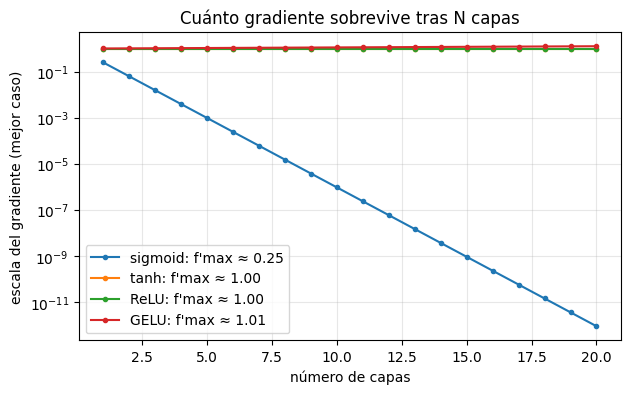

fracción de entradas en las que la neurona muerta se activa: 0.0
por tanto, su gradiente respecto a z siempre es           : 0.0


In [7]:
depths = np.arange(1, 21)
for name in ["sigmoid", "tanh", "ReLU", "GELU"]:
    f, df = ACTS[name]
    best_case = df(np.array([0.0 if name in ("sigmoid", "tanh") else 3.0]))[0]
    plt.semilogy(depths, best_case ** depths, marker="o", ms=3, label=f"{name}: f'max ≈ {best_case:.2f}")
plt.xlabel("número de capas"); plt.ylabel("escala del gradiente (mejor caso)")
plt.title("Cuánto gradiente sobrevive tras N capas"); plt.legend(); plt.show()

# Demostración de ReLU muerta: una neurona con un sesgo muy negativo nunca se activa.
dead = Neuron(2, relu); dead.b = -10.0
X = np.random.randn(1000, 2)
print("fracción de entradas en las que la neurona muerta se activa:", (dead.forward(X) > 0).mean())
print("por tanto, su gradiente respecto a z siempre es           :", d_relu(X @ dead.w + dead.b).max())

## 6. Una neurona como compuerta lógica

Con una activación escalón, elegir los pesos a mano da las compuertas lógicas clásicas. AND se activa solo si ambas entradas valen 1; OR se activa si al menos una vale 1.

**XOR** (exactamente una entrada vale 1) es imposible: no existe una sola recta que separe $\{(0,1),(1,0)\}$ de $\{(0,0),(1,1)\}$. Minsky y Papert lo señalaron en 1969 y contribuyó al primer "invierno de la IA". La solución es una **red** de neuronas, que el notebook 02 construye y entrena.

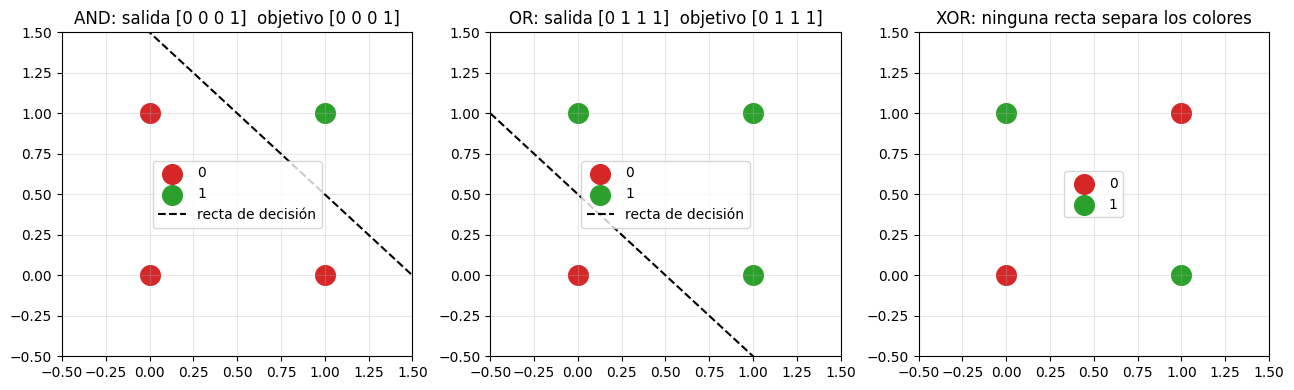

In [8]:
X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
gates = {"AND": (np.array([1.0, 1.0]), -1.5), "OR": (np.array([1.0, 1.0]), -0.5)}
targets = {"AND": [0, 0, 0, 1], "OR": [0, 1, 1, 1], "XOR": [0, 1, 1, 0]}

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, name in zip(axes, ["AND", "OR", "XOR"]):
    y = np.array(targets[name])
    ax.scatter(*X_bool[y == 0].T, s=200, c="tab:red", label="0")
    ax.scatter(*X_bool[y == 1].T, s=200, c="tab:green", label="1")
    if name in gates:
        w, b = gates[name]
        out = step(X_bool @ w + b)
        xs = np.linspace(-0.5, 1.5, 10)
        ax.plot(xs, -(w[0] * xs + b) / w[1], "k--", label="recta de decisión")
        ax.set_title(f"{name}: salida {out.astype(int)}  objetivo {y}")
    else:
        ax.set_title("XOR: ninguna recta separa los colores")
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5); ax.legend(loc="center")
plt.tight_layout(); plt.show()

## 7. Entrenar una neurona

Elegir los pesos a mano no escala. Queremos que la neurona los **aprenda** a partir de ejemplos.

### 7a. La regla de aprendizaje del perceptrón (Rosenblatt, 1958)

Para cada ejemplo mal clasificado, empuja un poco los pesos hacia él:
$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y - \hat y)\,\mathbf{x}, \qquad b \leftarrow b + \eta\,(y-\hat y)$$
Está garantizado que converge **si** los datos son linealmente separables.

errores de clasificación por época: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


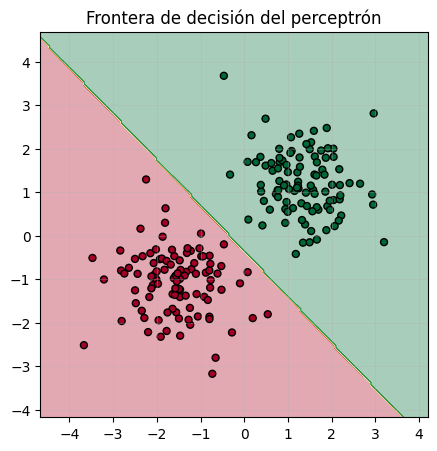

In [9]:
def make_blobs(n=200, seed=1):
    rng = np.random.default_rng(seed)
    a = rng.normal([-1.5, -1.0], 0.8, size=(n // 2, 2))
    b = rng.normal([1.5, 1.2], 0.8, size=(n // 2, 2))
    return np.vstack([a, b]), np.array([0] * (n // 2) + [1] * (n // 2))

X, y = make_blobs()
w, b, eta = np.zeros(2), 0.0, 0.1
errors_per_epoch = []
for epoch in range(20):
    errors = 0
    for xi, yi in zip(X, y):
        y_hat = step(np.array(xi @ w + b))
        if y_hat != yi:
            w += eta * (yi - y_hat) * xi
            b += eta * (yi - y_hat)
            errors += 1
    errors_per_epoch.append(errors)
print("errores de clasificación por época:", errors_per_epoch)

def plot_boundary(ax, predict, X, y, title):
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 200),
                         np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 200))
    P = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, P, levels=20, cmap="RdYlGn", alpha=0.35)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="RdYlGn", edgecolors="k", s=25)
    ax.set_title(title)

fig, ax = plt.subplots(figsize=(5, 5))
plot_boundary(ax, lambda P: step(P @ w + b), X, y, "Frontera de decisión del perceptrón")
plt.show()

### 7b. Descenso de gradiente con una neurona sigmoide (= regresión logística)

La función escalón tiene derivada cero, así que no podemos preguntar "¿en qué dirección debe moverse cada peso para reducir el error?". La cambiamos por la **sigmoide**, que es suave, interpretamos la salida como una probabilidad $\hat y = \sigma(z)$ y minimizamos la pérdida de **entropía cruzada binaria**:

$$ L = -\frac{1}{N}\sum_i \big[y_i \log \hat y_i + (1-y_i)\log(1-\hat y_i)\big] $$

La regla de la cadena da un gradiente bellamente simple (la derivada de la sigmoide cancela el logaritmo):

$$ \frac{\partial L}{\partial z_i} = \frac{\hat y_i - y_i}{N}, \qquad \frac{\partial L}{\partial \mathbf{w}} = X^\top \frac{\hat{\mathbf{y}} - \mathbf{y}}{N}, \qquad \frac{\partial L}{\partial b} = \text{media}(\hat{\mathbf{y}} - \mathbf{y}) $$

Después se repite: $\mathbf{w} \leftarrow \mathbf{w} - \eta \nabla_\mathbf{w} L$. Este bucle **es** toda la idea del entrenamiento, y todos los modelos, hasta los de la escala de GPT, lo usan.

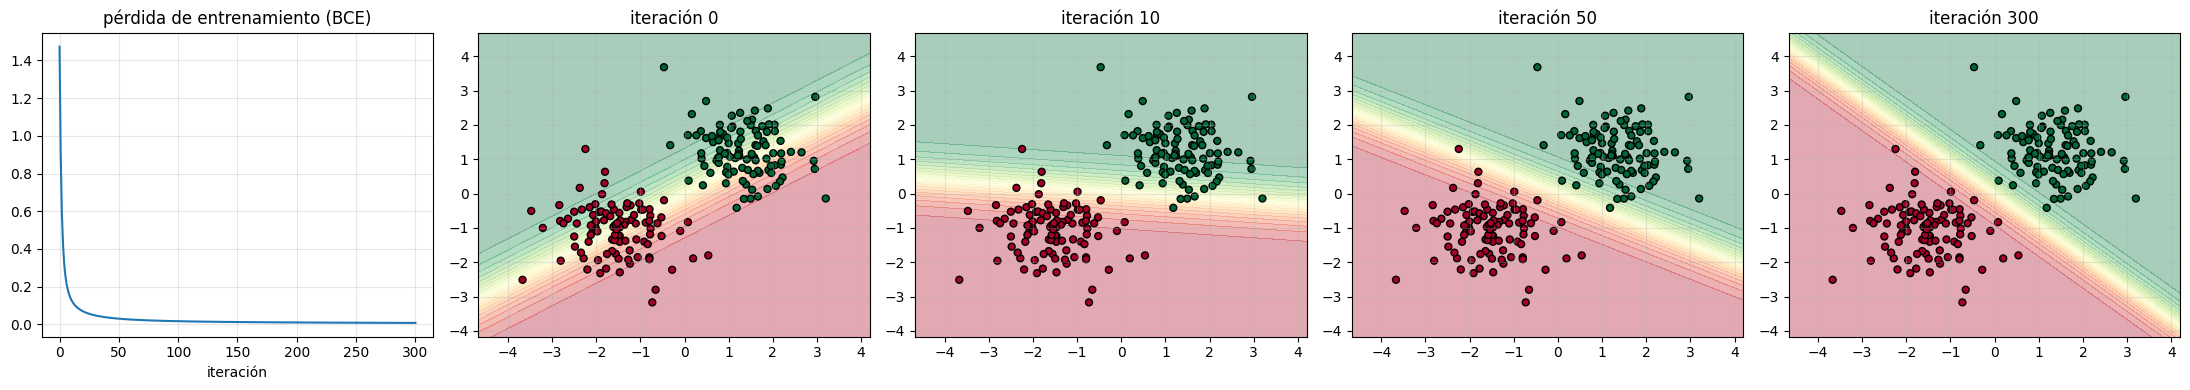

pérdida final 0.007, exactitud 100.0%, w=[2.89 3.16], b=-0.05


In [10]:
def bce(y_hat, y, eps=1e-12):
    y_hat = np.clip(y_hat, eps, 1 - eps)
    return -np.mean(y * np.log(y_hat) + (1 - y) * np.log(1 - y_hat))

neuron = Neuron(2, sigmoid)
neuron.w = np.array([-2.0, 2.0])         # inicio deliberadamente malo para ver cómo aprende
eta, history, snapshots = 0.5, [], {}
for it in range(301):
    y_hat = neuron.forward(X)
    history.append(bce(y_hat, y))
    grad_z = (y_hat - y) / len(y)
    neuron.w -= eta * (X.T @ grad_z)
    neuron.b -= eta * grad_z.sum()
    if it in (0, 10, 50, 300):
        snapshots[it] = (neuron.w.copy(), neuron.b)

fig, axes = plt.subplots(1, 5, figsize=(22, 4))
axes[0].plot(history); axes[0].set_title("pérdida de entrenamiento (BCE)"); axes[0].set_xlabel("iteración")
for ax, (it, (w_s, b_s)) in zip(axes[1:], snapshots.items()):
    plot_boundary(ax, lambda P: sigmoid(P @ w_s + b_s), X, y, f"iteración {it}")
plt.tight_layout(); plt.show()
acc = ((neuron.forward(X) > 0.5) == y).mean()
print(f"pérdida final {history[-1]:.3f}, exactitud {acc:.1%}, w={neuron.w.round(2)}, b={neuron.b:.2f}")

### La misma neurona, el mismo resultado, en PyTorch

Frameworks como PyTorch calculan los gradientes por nosotros (**diferenciación automática**). El notebook 02 abre esa caja negra.

In [11]:
import torch
torch.manual_seed(0)
Xt, yt = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)
layer = torch.nn.Linear(2, 1)                        # w y b
opt = torch.optim.SGD(layer.parameters(), lr=0.5)
for it in range(300):
    loss = torch.nn.functional.binary_cross_entropy_with_logits(layer(Xt).squeeze(1), yt)
    opt.zero_grad(); loss.backward(); opt.step()
print(f"PyTorch: pérdida {loss.item():.3f}, exactitud {((layer(Xt).squeeze(1) > 0).float() == yt).float().mean():.1%}")

PyTorch: pérdida 0.008, exactitud 100.0%


## Ideas clave

* Una neurona es una **suma ponderada + sesgo + activación no lineal**. Dibuja un hiperplano.
* Las activaciones se eligen por el **comportamiento de su gradiente**: las funciones de la familia ReLU mantienen vivos los gradientes; la sigmoide y la tanh se saturan. Los transformers modernos usan **GELU** o **SiLU** (variantes suaves de ReLU).
* **Softmax** convierte puntuaciones en probabilidades; la temperatura controla qué tan marcadas son.
* Entrenar = definir una pérdida, calcular su gradiente con la regla de la cadena, dar un paso cuesta abajo. Repetir.
* Una neurona no puede resolver XOR. Necesitamos **capas**, que son el tema del **notebook 02**.

## Ejercicios

1. Entrena la neurona sigmoide con `eta = 5.0` y con `eta = 0.01`. ¿Qué le pasa a la curva de pérdida?
2. Sustituye `sigmoid` por `tanh` en la sección 7b (transforma las etiquetas a −1/+1 y usa el error cuadrático medio). ¿Converge más rápido?
3. Encuentra a mano los pesos de una compuerta NAND. ¿Por qué se dice que NAND es "universal"?
4. Implementa la activación **Mish** $z\tanh(\ln(1+e^z))$ y su derivada; verifícala con diferencias finitas.
5. Genera nubes de puntos que se solapen mucho. ¿Qué le pasa a la regla del perceptrón? ¿Y al descenso de gradiente?